In [1]:
# import knihoven
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from uncertainties import ufloat as uf
from uncertainties import unumpy as unp
from pathlib import Path

# path config
downloads_dir = Path.home() / 'Downloads'
# ujistime se, ze slozka existuje (kdyby nahodou ne)
downloads_dir.mkdir(parents=True, exist_ok=True)
# output_path = downloads_dir / 'muj_graf.png'

In [2]:
# definice funkci

# nejistota typu A 
def unc_A(data):
    '''
    Výpočet nejistoty typu A
    data : list nebo numpy array
         měření
    return : float
        nejistota typu A
    '''
    data = np.array(data)
    n = len(data)

    s = np.std(data, ddof=1)
    u_A = s / np.sqrt(n)
    
    return u_A

def dms(stupne):
    stupne = np.asarray(stupne, dtype=float)
    znamenko = np.sign(stupne)
    celkem = np.abs(stupne) * 3600

    m_celkem, s = np.divmod(celkem, 60)
    d, m = np.divmod(m_celkem, 60)

    return znamenko, d, m, s

In [3]:
# nacteni google tabulek
sheet_id = '1WguDcMu3y95ozOn7a2cBLHqNAV9YbfoBmDYihw6zr6o'
gid = '0'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_hranol = pd.read_csv(url)
df_hranol.dropna()

,ψ₁ – stupně,ψ₁ – minuty,ψ₁ – vteřiny,ψ₂ – stupně,ψ₂ – minuty,ψ₂ – vteřiny
0,267,69,19,132,69,14
1,263,47,17,128,46,59
2,257,56,31,122,56,33
3,253,22,15,118,22,9
4,245,35,29,110,35,23


In [4]:
# lamavy uhel

psi1_df = df_hranol['ψ₁ – stupně'] + df_hranol['ψ₁ – minuty']/60 + df_hranol['ψ₁ – vteřiny']/3600
psi1 = psi1_df.to_numpy(dtype=float)

psi2_df = df_hranol['ψ₂ – stupně'] + df_hranol['ψ₂ – minuty']/60 + df_hranol['ψ₂ – vteřiny']/3600
psi2 = psi2_df.to_numpy(dtype=float)

omega = (180 - (psi1 - psi2))*np.pi/180


znamenko, d, m, s = dms(omega*180/np.pi)
#for u, zn, dd, mm, ss in zip(omega*180/np.pi, znamenko, d, m, s):
#    minus = "-" if zn < 0 else ""
#    print(f'{minus}{int(dd)} {int(mm):02d} {ss:05.2f}')


omega_uf = uf(np.mean(omega), unc_A(omega))
#print(omega_uf*180/np.pi)
omega_uf_n = omega_uf.n
znamenko, d, m, s = dms(omega_uf.std_dev*180/np.pi)
#print(znamenko, d, m, s)

In [5]:
# nacteni google tabulek
sheet_id = '1WguDcMu3y95ozOn7a2cBLHqNAV9YbfoBmDYihw6zr6o'
gid = '37383797'
url = f'https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}'

df_deviace = pd.read_csv(url)
df_deviace = df_deviace.dropna()
df_deviace

,Čára,Barva,λ [nm],φ₁ – stupně,φ₁ – minuty,φ₁ – vteřiny,φ₂ – stupně,φ₂ – minuty,φ₂ – vteřiny
0,1,Fialová,404.7,234,33,18,170,37,50
1,2,Fialová,407.8,234,31,15,170,39,34
2,3,Modrá,435.8,234,16,14,170,55,36
3,4,Modrozelená,491.6,233,55,26,171,17,29
4,5,Zelená,546.1,233,40,31,171,31,34
5,6,Žlutá,576.9,233,34,2,171,38,27
6,8,Červená,623.4,233,26,5,171,46,5


In [6]:
# deviace

phi1_df = df_deviace['φ₁ – stupně'] + df_deviace['φ₁ – minuty']/60 + df_deviace['φ₁ – vteřiny']/3600
phi1 = phi1_df.to_numpy(dtype=float)

phi2_df = df_deviace['φ₂ – stupně'] + df_deviace['φ₂ – minuty']/60 + df_deviace['φ₂ – vteřiny']/3600
phi2 = phi2_df.to_numpy(dtype=float)

delta_min = abs((phi1 - phi2)/2)*np.pi/180
delta_min_test = np.array([66, 66, 67, 69, 71, 74])*np.pi/180

# index lomu

n = np.sin((delta_min+omega_uf_n)/2)/np.sin(omega_uf_n/2)
for u in n:print(fr'${u:.4f}$')

$1.6261$
$1.6255$
$1.6209$
$1.6145$
$1.6102$
$1.6082$
$1.6058$


1.6076+/-0.0009
58.0+/-3.0


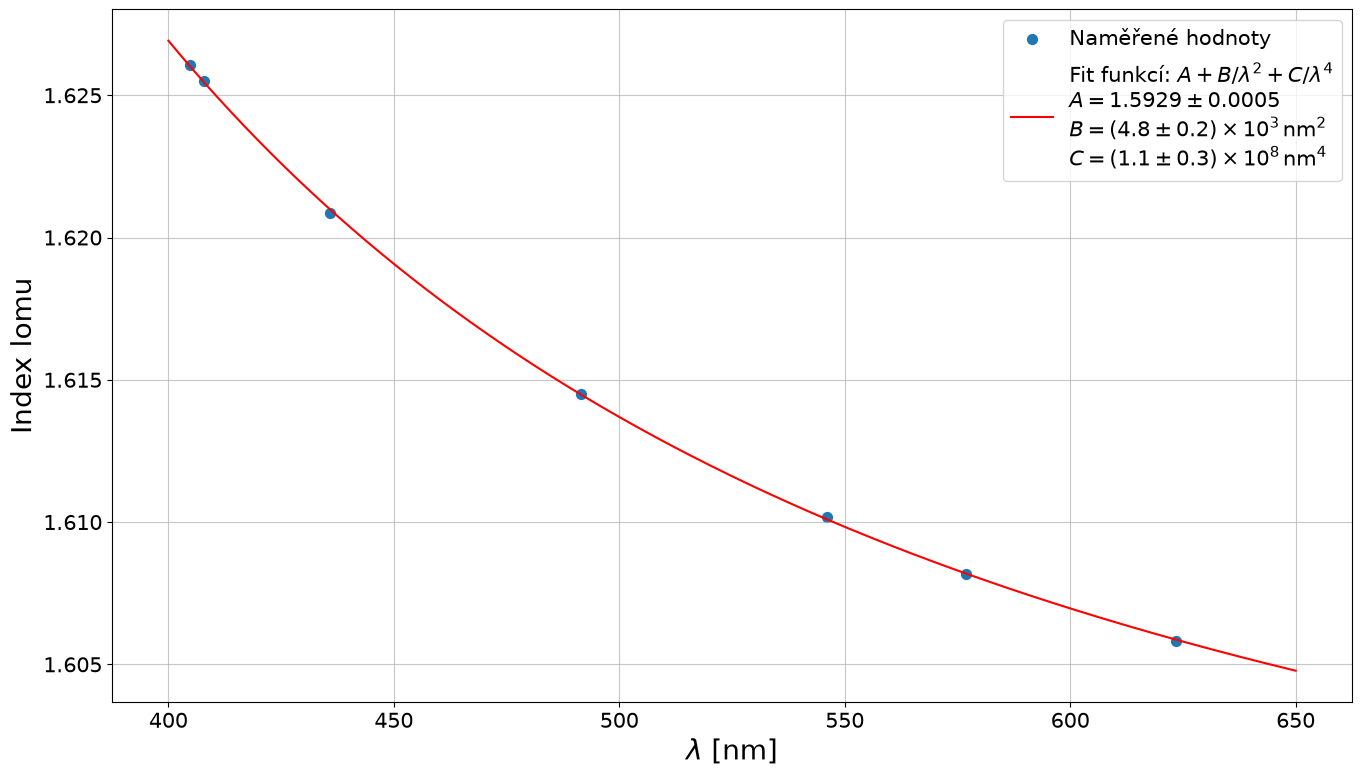

In [7]:
# cauchy fit
vln_delka = df_deviace['λ [nm]'].to_numpy(dtype=float)
vln_delka_lispace = np.linspace(400, 650, 1000)


def cauchy(delka_VLN, A, B, C):
    x_func = 1e4 /(delka_VLN**2)
    return A + B*x_func + C*x_func**2

p0 = [1.6, 0.05, 0.0]
popt, pcov = curve_fit(cauchy, vln_delka, n, p0=p0)
A, B, C = popt
unc_A, unc_B, unc_C = np.sqrt(np.diag(pcov))
B_nm,  unc_B_nm = B * 1e4,  unc_B * 1e4
C_nm,  unc_C_nm = C * 1e8,  unc_C * 1e8

A_uf = uf(A, unc_A)
B_uf = uf(B, unc_B)
C_uf = uf(C, unc_C)
#print(A, B_nm, C_nm)
#print(unc_A, unc_B_nm, unc_C_nm)

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_ylabel(r'Index lomu', fontsize=20)
ax.set_xlabel(r'$\lambda$ [nm]', fontsize=20)
ax.scatter(vln_delka, n, label='Naměřené hodnoty', s=50)
ax.plot(vln_delka_lispace, cauchy(vln_delka_lispace, *popt), color='red', linestyle='-',
    label=r'Fit funkcí: $A + B/\lambda^2 + C/\lambda^4$''\n'
    fr'$A = {uf(A, unc_A):.1uL}$''\n'
    fr'$B = {uf(B_nm, unc_B_nm):.1uL}\,\mathrm{{nm^2}}$''\n'
    fr'$C = {uf(C_nm, unc_C_nm):.1uL}\,\mathrm{{nm^4}}$')
ax.tick_params(labelsize=15)
ax.grid(True, alpha=0.7)
ax.legend(fontsize=15)
plt.savefig(downloads_dir / 'cauchy.pdf', dpi=300, bbox_inches='tight')
#np.max(((n - cauchy(vln_delka, *popt))/n)*100)

fraunhofer_d = cauchy(587.6, A_uf, B_uf, C_uf)
fraunhofer_F = cauchy(486.1, A_uf, B_uf, C_uf)
fraunhofer_C = cauchy(656.3, A_uf, B_uf, C_uf)

ny_d = (fraunhofer_d - 1)/(fraunhofer_F - fraunhofer_C)
print(fraunhofer_d)
print(ny_d)